# Issue #207 — active fixed-N7 bankroll allocation

This thin executed notebook verifies the immutable package and reads decision-useful outputs. Core reconstruction, controller, projection, settlement and metrics logic lives in `src/bankroll_policy/fixed_n7.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'results/issue-207').exists():
    ROOT = ROOT.parents[2]
RESULTS = ROOT / 'results/issue-207'
assert RESULTS.exists()

## Frozen boundary

CV-2021 fits model parameters, CV-2022 freezes risk choices, and CV-2023 is the one terminal historical evaluation. LOCKED_TEST outcomes remain embargoed. Cash and #206 NO_BET are safety references only.

In [2]:
import sys
sys.path.insert(0, str(ROOT / 'src'))
from bankroll_policy.fixed_n7 import verify
receipt = verify(RESULTS)
receipt

{'status': 'PASS',
 'files': 18,
 'manifest_sha256': 'be81155224fd9785a4e5cef851759ebecb5eafab72e6abbb22664f982ea9d592',
 'active_request_rows': 68880,
 'capital_ledger_rows': 13560,
 'engine_valid': True,
 'active_overlay_evidence': True,
 'deployable_policy': False}

In [3]:
decision = json.loads((RESULTS / 'decision.json').read_text())
pd.Series(decision, name='value').to_frame()

,value
ACTIVE_OVERLAY_EVIDENCE,True
DEPLOYABLE_POLICY,False
ENGINE_VALID,True
active_overlay_evidence_rule,matched K8 active funding; positive ending-cap...
controlling_k,8
deployable_policy_reason,NO_COMPARABLE_ACCEPTED_STAGE3_TICKET_BASELINE_...
locked_test_boundary,2025/2026 outcomes and official-final-SP label...
negative_freeze,None
next_issue,#208 receives schema/evidence only; remains bl...
qualifying_active_rows,1


In [4]:
summary = pd.read_csv(RESULTS / 'capital_summary.csv')
columns = ['policy','controller','risk_fraction','ending_capital_yuan','capital_growth_pct','turnover_yuan','active_support_roi','max_drawdown_pct']
summary.query("split == 'CV_2023' and k == 8").sort_values('ending_capital_yuan', ascending=False)[columns].head(15)

,policy,controller,risk_fraction,ending_capital_yuan,capital_growth_pct,turnover_yuan,active_support_roi,max_drawdown_pct
144,MARKET_WOR,NATIVE_2_YUAN,NaN,99245.378150,-0.007546,880.0,-0.857525,0.007546
120,MARKET_WR,NATIVE_2_YUAN,NaN,99120.000000,-0.008800,880.0,-1.000000,0.008800
168,LOGISTIC_BASELINE,NATIVE_2_YUAN,NaN,99120.000000,-0.008800,880.0,-1.000000,0.008800
216,TOP_K_EXPECTED,NATIVE_2_YUAN,NaN,99120.000000,-0.008800,880.0,-1.000000,0.008800
192,LEARNED_MLP,NATIVE_2_YUAN,NaN,99120.000000,-0.008800,880.0,-1.000000,0.008800
150,MARKET_WOR,SIMPLE_LOGISTIC,0.01,65528.739368,-0.344713,44000.0,-0.783438,0.344713
145,MARKET_WOR,EQUAL_1PCT,0.01,62178.638581,-0.378214,43338.0,-0.872707,0.378214
151,MARKET_WOR,BOUNDED_NEURAL,0.01,59774.941141,-0.402251,42858.0,-0.938566,0.402251
199,LEARNED_MLP,BOUNDED_NEURAL,0.01,57580.000000,-0.424200,42420.0,-1.000000,0.424200
217,TOP_K_EXPECTED,EQUAL_1PCT,0.01,57580.000000,-0.424200,42420.0,-1.000000,0.424200


In [5]:
matched = pd.read_csv(RESULTS / 'matched_comparisons.csv')
matched.query("k == 8 and comparison_role == 'EQUAL_FUNDING_CONTROL'")[['policy','candidate_controller','comparator_controller','equal_capital_schedule','matched_lift_ending_capital_yuan','matched_lift_max_drawdown_pct','identifiability']].head(15)

,policy,candidate_controller,comparator_controller,equal_capital_schedule,matched_lift_ending_capital_yuan,matched_lift_max_drawdown_pct,identifiability
0,MARKET_WR,SCORE_WEIGHTED_5PCT,EQUAL_5PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
1,MARKET_WR,SIMPLE_LOGISTIC,EQUAL_1PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
2,MARKET_WR,BOUNDED_NEURAL,EQUAL_1PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
9,MARKET_WOR,SCORE_WEIGHTED_5PCT,EQUAL_5PCT,True,-125.378150,-0.001254,IDENTIFIED_MATCHED_ACTIVE_FUNDING
10,MARKET_WOR,SIMPLE_LOGISTIC,EQUAL_1PCT,True,4012.100786,0.040121,IDENTIFIED_MATCHED_ACTIVE_FUNDING
11,MARKET_WOR,BOUNDED_NEURAL,EQUAL_1PCT,True,-2883.697440,-0.028837,IDENTIFIED_MATCHED_ACTIVE_FUNDING
18,LOGISTIC_BASELINE,SCORE_WEIGHTED_5PCT,EQUAL_5PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
19,LOGISTIC_BASELINE,SIMPLE_LOGISTIC,EQUAL_1PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
20,LOGISTIC_BASELINE,BOUNDED_NEURAL,EQUAL_1PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING
27,LEARNED_MLP,SCORE_WEIGHTED_5PCT,EQUAL_5PCT,True,0.000000,0.000000,IDENTIFIED_MATCHED_ACTIVE_FUNDING


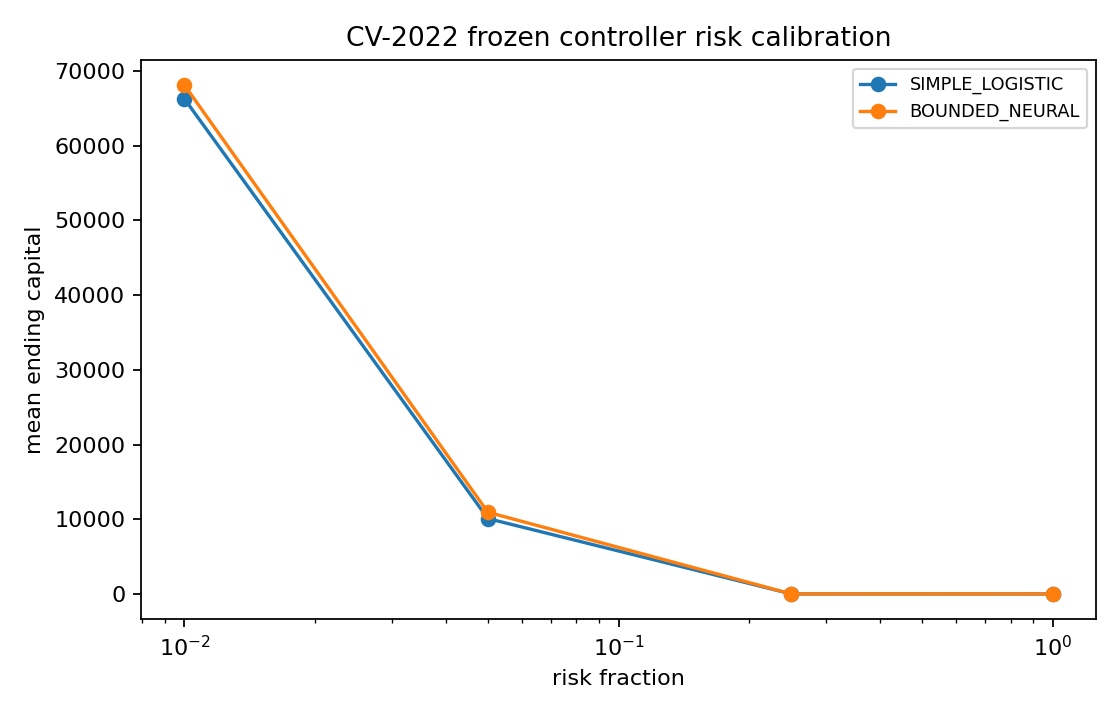

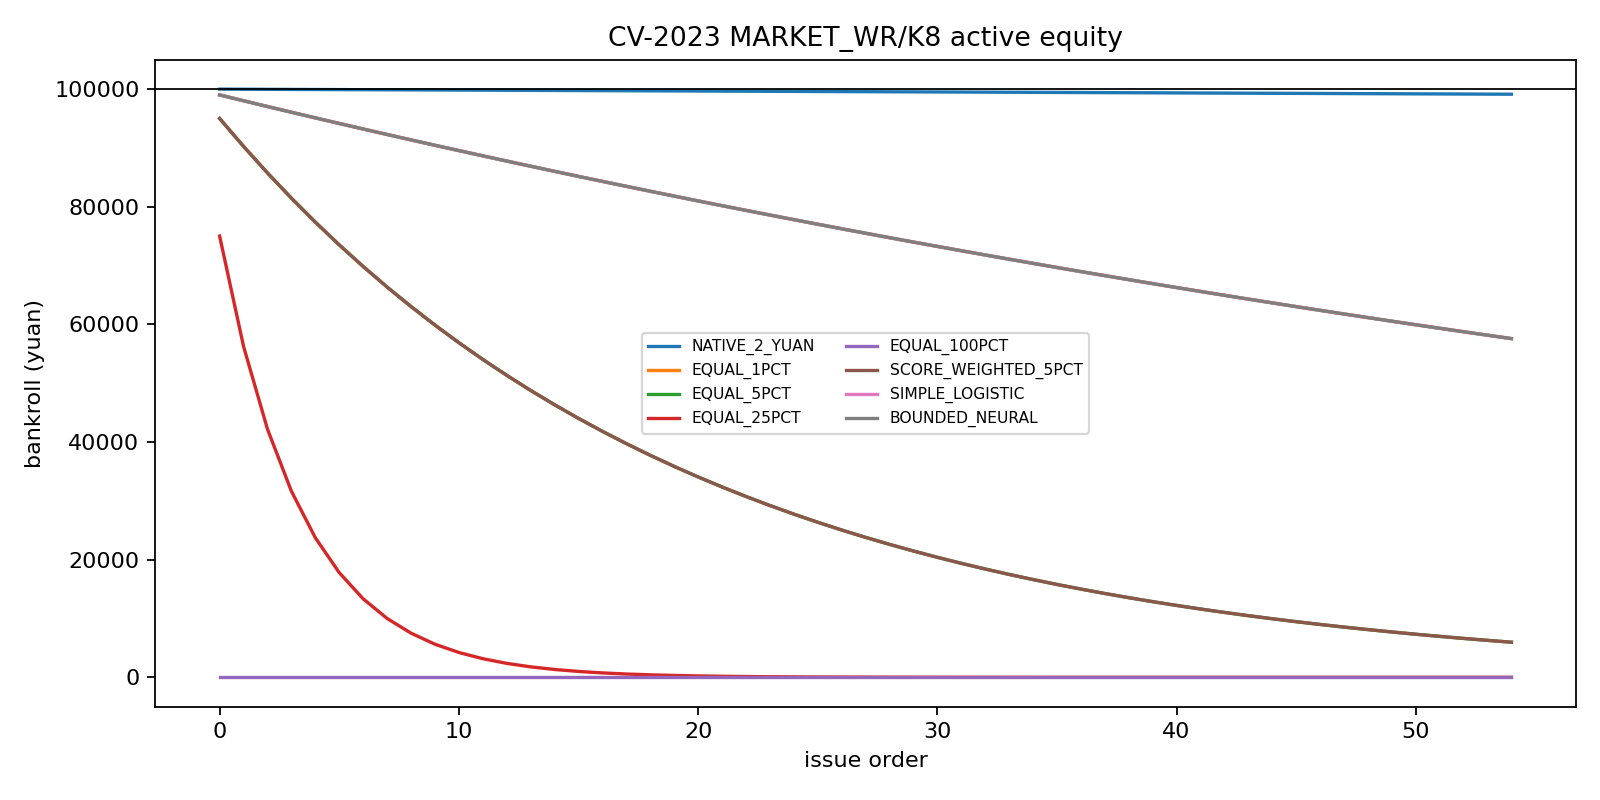

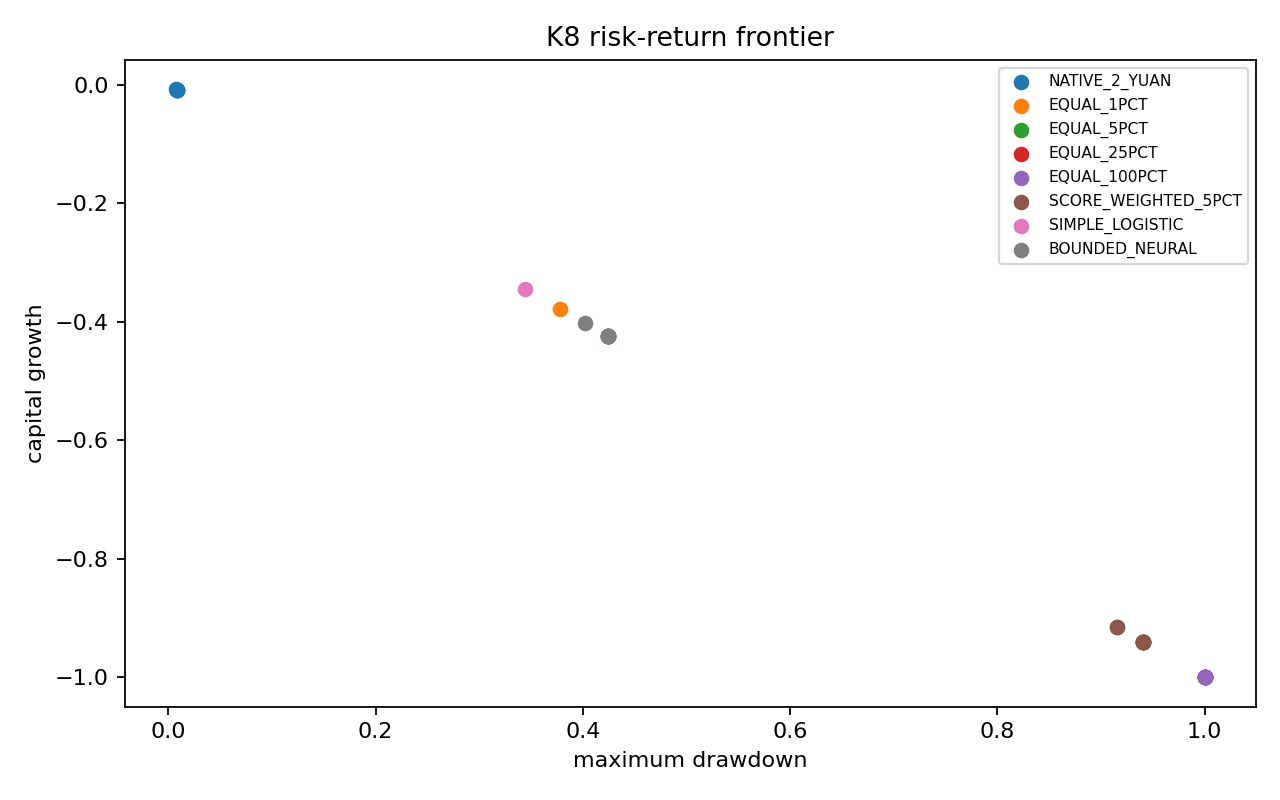

In [6]:
for name in ('parameter_performance.png', 'equity_paths.png', 'risk_return_frontier.png'):
    display(Image(filename=str(RESULTS / name)))

## Interpretation

The controlling conclusion comes from active matched schedules, not cash. A negative result freezes the native ¥2 active control; it does not claim cash is the optimal Stage-4 model. `DEPLOYABLE_POLICY` remains false until an accepted comparable Stage-3 ticket baseline and later confirmation exist.